# 1. Clean the data and explore it (EDA)

**Goal:** make sure the photos and labels can be trusted, then understand what is in the data before training anything.

**Dataset:** DeepDRiD regular fundus photos. **Label:** diabetic retinopathy (DR) grade from 0 to 4.

| Grade | Meaning | Referable? |
|---|---|---|
| 0 | No DR | No |
| 1 | Mild | No |
| 2 | Moderate | Yes |
| 3 | Severe | Yes |
| 4 | Proliferative | Yes |

Run every cell from top to bottom. First make sure this notebook uses your `.venv` kernel.

In [1]:
%pip install -q numpy pandas scipy pillow matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "DeepDRiD" / "regular_fundus_images"
PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
for folder in (PROCESSED, RESULTS, MODELS):
    folder.mkdir(parents=True, exist_ok=True)
print("Project folder:", ROOT)

Project folder: c:\Users\Administrator\Desktop\AfriEyeSamsung


In [3]:
import hashlib

import numpy as np
import pandas as pd
from PIL import Image

In [4]:
import matplotlib.pyplot as plt

BLUE, TEAL, ORANGE, PURPLE = "#1F4E9E", "#00948F", "#C4581F", "#7A3E9D"
INK, MUTED, GRID = "#1B2433", "#566173", "#E3E7F0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.edgecolor": "#AEB6C5", "axes.labelcolor": MUTED, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "legend.frameon": False,
})

## Load the labels

The dataset gives us three parts, already separated by patient. We keep that split so that nobody appears in both training and testing.

In [5]:
def load_split(folder_name, split):
    folder = RAW / folder_name
    d = pd.read_csv(folder / f"{folder_name}.csv")
    d["grade"] = d["left_eye_DR_Level"].fillna(d["right_eye_DR_Level"])
    d = d.rename(columns={"Overall quality": "quality"})
    d["split"] = split
    d["path"] = [str(folder / "Images" / str(p) / f"{i}.jpg") for p, i in zip(d.patient_id, d.image_id)]
    return d[["patient_id", "image_id", "grade", "quality", "split", "path"]]


def load_test():
    folder = RAW / "Online-Challenge1&2-Evaluation"
    grades = pd.read_excel(folder / "Challenge1_labels.xlsx").rename(columns={"DR_Levels": "grade"})
    quality = pd.read_excel(folder / "Challenge2_labels.xlsx").rename(columns={"Overall quality": "quality"})
    d = grades.merge(quality[["image_id", "quality"]], on="image_id", how="left")
    d["patient_id"] = d.image_id.str.split("_").str[0].astype(int)
    d["split"] = "test"
    d["path"] = [str(folder / "Images" / str(p) / f"{i}.jpg") for p, i in zip(d.patient_id, d.image_id)]
    return d[["patient_id", "image_id", "grade", "quality", "split", "path"]]


data = pd.concat([load_split("regular-fundus-training", "train"), load_split("regular-fundus-validation", "val"), load_test()], ignore_index=True)
print(data.shape)
print(data.head().drop(columns="path").to_string(index=False))

(2000, 6)
 patient_id image_id  grade  quality split
          1     1_l1    0.0        0 train
          1     1_l2    0.0        0 train
          1     1_r1    0.0        0 train
          1     1_r2    0.0        0 train
          2     2_l1    2.0        0 train


## Clean the data

We check for each problem that could damage the results, and record how many rows it affects.

**We do not remove poor-quality photos.** Community health workers will also take poor photos, so the model must meet them in testing. We keep the quality label and look at it below.

In [6]:
report = []

def check(name, bad_rows):
    report.append({"check": name, "rows affected": int(len(bad_rows))})
    return bad_rows

no_grade = check("Missing grade", data[data.grade.isna()])
bad_grade = check("Grade outside 0 to 4", data[data.grade.notna() & ~data.grade.isin([0, 1, 2, 3, 4])])
no_quality = check("Missing quality label", data[data.quality.isna()])
duplicate_ids = check("Repeated image ID", data[data.image_id.duplicated(keep=False)])
missing_files = check("Image file missing", data[[not Path(p).exists() for p in data.path]])

sizes, hashes, unreadable = {}, {}, []
for row in data.itertuples():
    if not Path(row.path).exists():
        continue
    try:
        raw = Path(row.path).read_bytes()
        hashes[row.image_id] = hashlib.md5(raw).hexdigest()
        with Image.open(row.path) as image:
            image.verify()
        with Image.open(row.path) as image:
            sizes[row.image_id] = image.size
    except Exception:
        unreadable.append(row.image_id)

data["width"] = data.image_id.map(lambda i: sizes.get(i, (np.nan, np.nan))[0])
data["height"] = data.image_id.map(lambda i: sizes.get(i, (np.nan, np.nan))[1])
data["md5"] = data.image_id.map(hashes)
check("Image cannot be opened", data[data.image_id.isin(unreadable)])
same_file = check("Exact same image file repeated", data[data.md5.notna() & data.md5.duplicated(keep=False)])

in_splits = data.groupby("patient_id").split.nunique()
leaking = check("Patient in more than one split", data[data.patient_id.isin(in_splits[in_splits > 1].index)])

print(pd.DataFrame(report).to_string(index=False))

                         check  rows affected
                 Missing grade              0
          Grade outside 0 to 4              0
         Missing quality label              0
             Repeated image ID              0
            Image file missing              0
        Image cannot be opened              0
Exact same image file repeated              0
Patient in more than one split              0


In [7]:
remove = set(no_grade.image_id) | set(bad_grade.image_id) | set(missing_files.image_id) | set(unreadable)
clean = data[~data.image_id.isin(remove)].copy()
clean["grade"] = clean.grade.astype(int)
clean["referable"] = (clean.grade >= 2).astype(int)
clean["eye"] = clean.image_id.str.split("_").str[1].str[0].map({"l": "left", "r": "right"})

clean.drop(columns="md5").to_csv(PROCESSED / "clean_labels.csv", index=False)
print(f"Kept {len(clean):,} of {len(data):,} photos from {clean.patient_id.nunique()} patients.")
print("Saved data/processed/clean_labels.csv")

Kept 2,000 of 2,000 photos from 500 patients.
Saved data/processed/clean_labels.csv


## Explore: how many photos are in each grade?

**Why it matters:** if one grade dominates, a model can look accurate while missing the rarer grades.

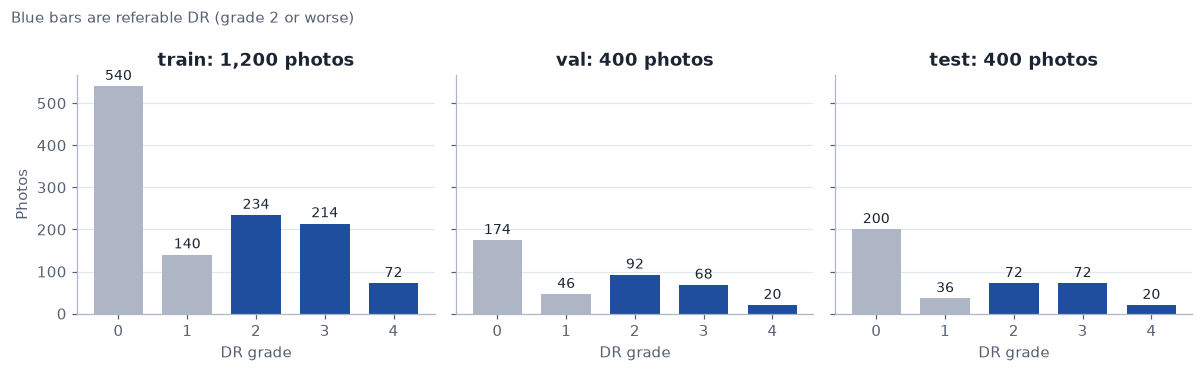

split
train    43.3
val      45.0
test     41.0


In [8]:
NAMES = ["0 No DR", "1 Mild", "2 Moderate", "3 Severe", "4 Proliferative"]
counts = clean.groupby(["split", "grade"]).size().unstack(fill_value=0).loc[["train", "val", "test"]]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, split in zip(axes, counts.index):
    values = counts.loc[split]
    colors = ["#AEB6C5", "#AEB6C5", BLUE, BLUE, BLUE]
    bars = ax.bar(range(5), values, color=colors, width=.72)
    ax.bar_label(bars, padding=2, color=INK, fontsize=9)
    ax.set_xticks(range(5), ["0", "1", "2", "3", "4"]); ax.set_title(f"{split}: {values.sum():,} photos"); ax.grid(axis="x", visible=False); ax.set_xlabel("DR grade")
axes[0].set_ylabel("Photos")
fig.suptitle("Blue bars are referable DR (grade 2 or worse)", x=.01, ha="left", fontsize=10, color=MUTED)
fig.tight_layout(); plt.show()
print(clean.groupby("split").referable.mean().mul(100).round(1).rename("% referable").loc[["train", "val", "test"]].to_string())

## Explore: photos per patient, and quality

**Why patients matter:** photos from one person look alike. That is why the split and all confidence intervals work by patient.

**Why quality matters:** a poor photo can hide disease. We compare the share labelled good across grades.

Photos per patient: {4: 500}


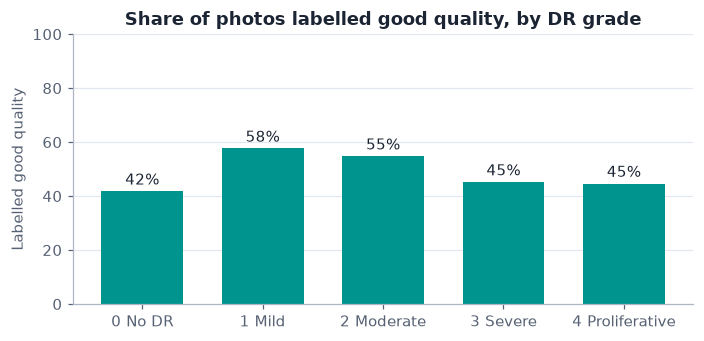

In [9]:
per_patient = clean.groupby("patient_id").size().value_counts().sort_index()
print("Photos per patient:", per_patient.to_dict())
share = clean.groupby("grade").quality.mean().mul(100)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
bars = ax.bar(NAMES, share, color=TEAL, width=.68)
ax.bar_label(bars, fmt="%.0f%%", padding=2, color=INK)
ax.set_ylim(0, 100); ax.set_ylabel("Labelled good quality"); ax.set_title("Share of photos labelled good quality, by DR grade"); ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

## Explore: image sizes

Different sizes can reveal different cameras. A model could learn the camera instead of the disease, so we do **not** use image size as a feature later.

In [10]:
print(clean.groupby(["width", "height"]).size().sort_values(ascending=False).head(8).rename("photos").to_string())
print()
print(pd.crosstab([clean.width, clean.height], clean.referable, normalize="index").mul(100).round(0).rename(columns={0: "% not referable", 1: "% referable"}).head(8).to_string())

width  height
1736   1824      1294
1976   1984       660
1734   1821        18
2230   1725        10
2232   1727        10
1592   1728         8

referable     % not referable  % referable
width height                              
1592  1728               25.0         75.0
1734  1821               89.0         11.0
1736  1824               72.0         28.0
1976  1984               26.0         74.0
2230  1725               80.0         20.0
2232  1727               80.0         20.0


## See the photos

Look at the photos yourself. Compare the grades, and notice how much colour and brightness vary between them.

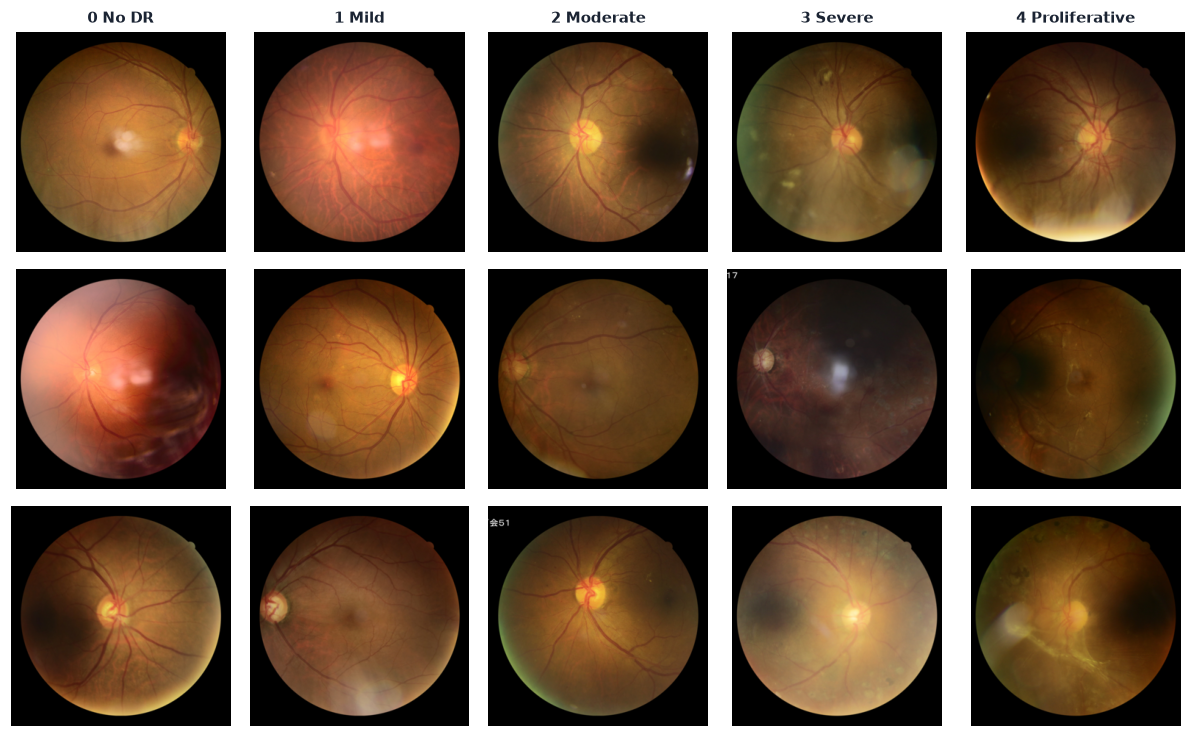

In [11]:
rng = np.random.default_rng(7)
fig, axes = plt.subplots(3, 5, figsize=(11, 6.8))
for g in range(5):
    picks = clean[clean.grade == g].sample(3, random_state=7)
    for r, row in enumerate(picks.itertuples()):
        image = Image.open(row.path).convert("RGB"); image.thumbnail((300, 300))
        axes[r, g].imshow(image); axes[r, g].axis("off")
        if r == 0: axes[r, g].set_title(NAMES[g], fontsize=10)
fig.tight_layout(); plt.show()

## Explore: do brightness and colour differ by grade?

We use 400 training photos, so this runs quickly. A big overlap means that simple colour alone will not separate the grades.

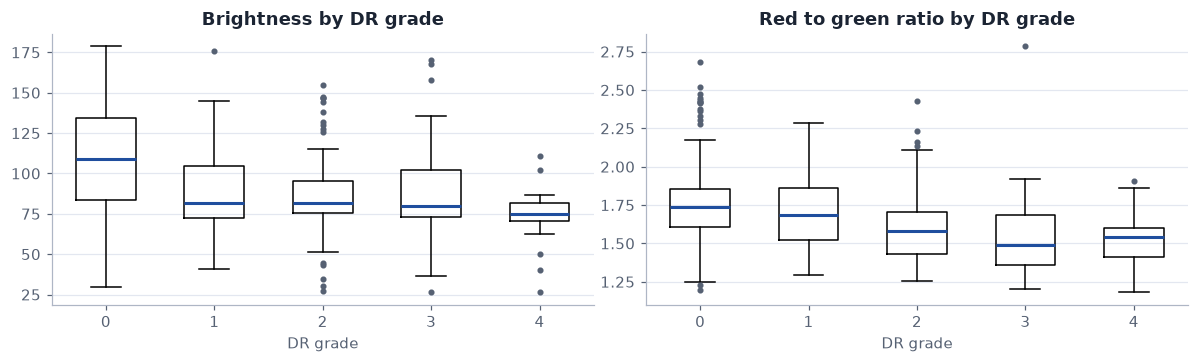

In [12]:
sample = clean[clean.split == "train"].sample(400, random_state=7)
rows = []
for row in sample.itertuples():
    image = Image.open(row.path).convert("RGB"); image.thumbnail((128, 128)); a = np.asarray(image, dtype=float)
    keep = a.max(axis=2) > 20
    rows.append({"grade": row.grade, "brightness": a[keep].mean(), "red_to_green": a[..., 0][keep].mean() / max(1, a[..., 1][keep].mean())})
look = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, title in zip(axes, ["brightness", "red_to_green"], ["Brightness", "Red to green ratio"]):
    ax.boxplot([look[look.grade == g][col] for g in range(5)], tick_labels=["0", "1", "2", "3", "4"], widths=.55, medianprops={"color": BLUE, "linewidth": 2}, flierprops={"markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": MUTED})
    ax.set_title(f"{title} by DR grade"); ax.set_xlabel("DR grade"); ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

## What we learned

Check the printed numbers above, then note:

1. Which grades are rare, and how many referable photos each split has.
2. Whether any cleaning check found a problem.
3. Whether quality differs by grade, which could mislead a quality check.
4. Whether image size is linked to the grade, which would be a warning sign of a shortcut.

**Warning from this dataset:** 74% of the 1976 x 1984 photos are referable, compared with 28% of the 1736 x 1824 photos. Size may point to different cameras or clinics, so a model could partly learn the source of a photo instead of the disease. Notebook 7 tests this.

**Next:** open `02_image_features.ipynb`.